# Network Analysis 기초


- https://chaelist.github.io/docs/network_analysis/network_basics/


#### 참고
- https://velog.io/@beoms96/Networkx-Book-1#12-%EB%84%A4%ED%8A%B8%EC%9B%8C%ED%81%AC-%EA%B3%BC%ED%95%99%EC%9D%98-%EB%B2%94%EC%9C%84

- https://brain-nim.tistory.com/35

- https://bab2min.tistory.com/554

In [5]:
from IPython.display import Image

## Network 기본 개념
### Node와 Edge
- Network: Node와 Edge로 이루어진 자료 구조.
- Node: vertex라고도 부르며, network를 이루는 각 점을 의미한다. ex) twitter user network를 만든다면, user들이 각각의 node.
- Edge: link, 또는 tie라고도 부르며, 각 node 간의 관계를 의미한다. ex) twitter user network를 만든다면, user(=node)간 follow 관계를 edge로 표현할 수 있다.
### Tie(관계)의 종류
- 비대칭 관계(asymmetric tie): 관계에서 두 node가 갖는 특성이 다른 경우.
    * 관계에 방향성이 있으므로, directed tie라고도 한다.
    * ex) SNS에서의 follower - followee 관계 (A가 B를 follow하면 A → B와 같이 관계의 방향이 존재)
    * directed tie로 구성된 네트워크를 directed network라고 함
- 대칭 관계 (symmetric tie): 관계에서 두 node가 갖는 특성이 비슷한 경우
    * 관계에 방향성이 없으므로, undirexted tie라고도 한다.
    * ex) 특정 집단 내 사람들 간의 친분 관계. (서로 아는 사이인지)
    * undirected tie로 구성된 네트워크를 undirected network라고 함


## 네트워크 중심성(Centrality) 척도

- 네트워크 그래프는 세상의 많은 관계들을 수학적으로 나타내는 강력한 도구
- 관계의 주체가 되는 행위자들은 Node로, 관계들은 Node사이를 연결하는 Edge
- 주변에서 찾아볼 수 있는 관계를 수학적인 형태의 Graph로 바꾸면 여러 가지가 가능해지는데, 그 중 대표적인것이 중심성(Centrality)
- 중심성은 그래프 상에서 어떤 Node가 가장 중요한지를 살피는 척도
(Zafarani, R., Abbash, M.A., & Liu, H, 2014, Social Media Mining : An introduction)



### 무방향성, 가중치 없는 네트워크 그래프 예시

![nn](image/01.png)

- 사실 누가봐도 노드 E가 제일 중요해보이지만, 이를 수학적으로 계산 가능
- 먼저 위의 그래프는 5개의 노드로 이루어져 있으므로, 5x5 인접행렬 A로 나타낼 수 있음

![nn](image/02.png)
- A_ij는 노드 i가 j와 연결되어있는지를 나타냄
- 위에서 예를 든것처럼 방향성이 없는 그래프의 경우에는 A_ij가 A_ji와 동일
- 또한 간선 가중치가 없으므로 행렬의 각 성분이 가질 수 있는 값은 0(연결 안됨) 또는 1(연결 됨)
- 만약 방향성이 있다면 A_ij가 A_ji와 다름
- 만약 간선 가중치가 있으면 행렬의 각 성분의 값은 가중치 적용

### - **연결 중심성(Degree Centrality, Cd)**

- Cd는 가장 간단한 중심성 척도. 한 Node에 연결된 모든 Egde의 갯수(Weighted 그래프일 경우에는 모든 Weight의 합)로 중심성을 평가
- 방향성이 있는 그래프일 경우에는 Node로 들어오는 Edge와 나가는 Edge가 다름
- In-degree만 계산할 경우 그 노드의 인기도를 볼 수 있고, Out-degree만 계산할 경우 그 노드의 영향력을 살필수 있음

- 하지만 단순 Cd로는 다른 네트워크끼리 중심성 비교를 수행하기 어려움 : 규모가 큰 네트워크일수록 당연히 Cd값도 커지기 때문에 공정한 비교가 어려움
- 따라서 정규화를 하여 사용하기도 함 :
  - 정규화 방법에는 네트워크 내 가능한 최대 Cd값인 N-1(N은 모든 노드의 숫자)으로 나누어 정규화
  - 실제로 해당 네트워크 내에서 나오는 가장 큰 Cd값으로 나누어 정규화
  - 네트워크 내의 모든 Cd값의 합으로 나누어 정규화



- 위의 예시에 적용해보면 E에 연결된 간선이 4개로 가장 많으므로 E가 가장 중심성이 높다고 볼수 있음
- 모든 노드의 Cd값을 편의상 하나의 벡터로 나타낼 수도 있는데 그러면 위의 예시에서의 Cd값은 다음과 같이 표현할 수 있음
![nn](image/03.png)

- 사실 누가봐도 노드 E가 제일 중요해보이지만, 이를 수학적으로 계산 가능
- Cd를 계산하는 수식은 다음과 같음

![nn](image/04.png) 
- 여기서 1은 모든 성분의 값이 1인 1xN차 행렬

### - **매개 중심성(Betweenness Centrality, Cb)**

- 이 중심성 척도는 노드들 간의 최단 경로를 가지고 계산 : A도시의 중요성을 보기 위해서는 A를 제외한 도시에 사는 사람들이 다른 도시로 이동할때 얼마나 A를 거쳐가는지를 살펴보면 된다는 아이디어를 바탕으로 함
- 그래프 이론의 용어로 다시 써보자면, 노드 A의 중요성은 A가 아닌 X, Y노드에 대해 X-Y의 최단 경로에 A가 포함되어있는 비율로 볼 수 있음
- 이 경우 노드 X에서 Y로 지나가는 최단 경로들이 항상 A를 거쳐간다면 그 값은 1
- 반대로 노드 X,Y에 대해서 X에서 Y로 지나가는 최단 경로들이 하나도 A를 거쳐가지 않으면 그 값은 0이 됩니다. 이 값들을 A를 제외한 모든 노드들에 계산하여 합치면 그 값이 바로 Cb

- Cb값도 네트워크 규모에 따라 그 크기가 달라질 수 있으니 다른 네트워크와 비교하기 위해서는 정규화 필요
  - 가능한 최대의 Cb값으로 나누어 정규화 :
  - 전체 노드의 갯수가 N개라고 하면, 한 노드 A를 선택하고 남은 노드의 갯수는 N-1개
  - N-1개 중에서 순서 상관없이 2개를 뽑는 경우는 총 (N-1) * (N-2) / 2가지
  - 이 값들이 모두 1이 나오는 경우가 최대값일테니 노드 갯수가 N인 네트워크의 최대 Cb값은 (N-1) * (N-2) / 2
  - 이 값으로 나눠서 정규화시키면 정규화된 Cb값은 항상 0~1사이에 위치


![nn](image/01.png)

노드 A의 매개 중심성
- A를 제외한 B~E들 간의 이동경로를 살펴봐야 함
- B-C, B-D, B-E, C-D, C-E, D-E 중 어떤 경우도 A를 거쳐가는 일이 없음
- 그러므로 이 경우는 계산할 것도 없이 Cb(A) = 0

노드 B의 매개 중심성
- A-C, A-D, A-E, C-D, C-E, D-E 중에서 A-C의 경우 A-B-C 또는 A-E-C를 거쳐가는 경우가 최단 경로
- 따라서 A-C의 경우 B를 거쳐갈 확률이 0.5
- 나머지는 경우는 없으므로 Cb(B) = 0.5입니다.

노드 E의 매개 중심성
- A-B, A-C, A-D, B-C, B-D, C-D 중에서 A-C의 경우 A-B-C, A-E-C의 경로가 있으므로 이 경우 E를 거칠 확률이 0.5
- A-D의 경우는 A-E-D밖에 없으므로 확률이 1
- B-D의 경우 B-E-D 밖에 없으므로 이 경우도 1
- C-D의 경우 역시 C-E-D 밖에 없으므로 1입니다. 따라서 Cb(E) = 0.5 + 1 + 1 + 1 = 3.5

모든 중심성 값을 구해 벡터 형태로 표현하면
![nn](image/05.png)

### - **근접 중심성(Closeness Centrality, Cc)**

- 근접 중심성은 중요한 노드일수록 다른 노드까지 도달하는 경로가 짧을 것이라는 가정에 기반
- 도시에 비유하자면, A도시에 사는 사람이 전국 각지로 가는데 걸리는 시간 평균과 B도시에 사는 사람이 전국 각지로 가는데 걸리는 시간 평균을 비교해서 A가 더 짧다면 더 중심적인 도시
- 이를 수학적으로 계산하기 위해서 한 노드 A에서 A를 제외한 다른 노드들까지의 최단 경로의 길이를 평균을 내고, 그 값을 역수로 취함 (길이가 짧을수록 Cc값이 커져야하므로)
- 수식은 다음과 같음

![nn](image/06.png)
(l은 두 노드 사이의 최단거리)

- 위의 그래프를 가지고 실제로 계산을 해보자면 A는 거리가 B까지 1, C까지는 2, D까지도 2, E까지는 1
- 따라서 A의 다른 노드까지의 평균거리는 1.5이므로 Cc(A) = 0.667


다른 경우도 모두 계산해서 벡터형태로 나타내면
![nn](image/07.png)

### - **고유벡터 중심성(Eigenvector Centrality, Ce)**

- 하지만 무조건 연결된 노드가 많다고 중요한 노드가 되는 것은 아니며, 중요한 노드와 많이 연결된 노드가 더 중요 (페북 친구가 아무리 많다고 해서 유명인사인건 아님 유명인사인 친구가 많을수록 유명인사)
- Cd는 단순히 연결된 노드의 숫자만 살핀다는 점에서 약점이 있음. 그래서 Ce에서는 중심성을 계산할때 다른 노드의 중심성을 반영해서 계산

![nn](image/13.png)
- A가 네트워크의 NxN 인접행렬이고 Ce가 중심성 값을 나타내는 1xN 행렬이라고 하면 위와 같은 식을 도출할 수 있음
- 선형대수론을 따르면 이때 Ce는 A의 고유벡터, λ는 고윳값
- 인접행렬을 가지고 적절한 λ값에 대한 고유벡터를 계산하면 이것이 중심성을 나타내는데 쓰일수 있

- A가 5x5 행렬이기 때문에 가능한 고윳값이 5개가 나오는데, 가장 큰 고윳값 2.686...에 대응하는 고유벡터를 구하면 다음과 같음 (복잡한 계산식은 생략)


![nn](image/14.png)

마찬가지로 E가 1.247로 제일 중요한 노드로 나옴


### - **Katz 중심성(Katz Centrality, Ck)**

- Ce의 한계 중 하나는 방향성 비순환 그래프와 같이 특별한 경우에는 중심성이 0이 나오는 경우가 있음
- 이를 방지하기 위해 모든 노드 중심성에 특정한 상수값을 더하는 방식이 Katz에 의해 제안 (고유벡터 중심성의 변형버전)

![nn](image/11.png)
(l은 모든 성분이 l인 lxN 행렬)

- 대게 α < 1/λ이 되도록 잡고 (λ는 A의 고유값 중 가장 큰 값),  β는 적절한 값으로 실험을 통해 설정
- α = 0.3,  β = 0.2 로 잡고 계산하면 다음과 같은 Ck값을 얻을 수 있음

![nn](image/12.png)




### - **페이지랭크(PageRank, Cp)**

- Cp가 지금까지 등장한 중심성 알고리즘 가장 성공한 알고리즘으로, Katz 중심성의 개량 버전
- Katz 중심성 계산식에서는 한 노드의 중요성이 연결된 다른 노드로 전부 전파되는 특징이 있음
- 다르게 말하자면 한 노드가 매우 중요하게 계산될 경우, 그와 연결된 노드들도 같이 덩달아 중요도가 높아져버리는 문제가 생길 수 있음
- 그렇기에 페이지랭크에서는 각 노드의 영향력을 다른 노드로 전파할 때, 외부로 향하는 모든 간선의 수(역시나 Weighted 그래프일 경우에는 Weight의 합)로 나누어 Out-edge로 영향력이 지나치게 퍼지는 것을 방지

![nn](image/08.png)
(D는 각 노드의 외부로 향하는 간선의 수를 성분으로 가지는 NxN 대각행렬)

-  외부로 향하는 간선이 없는 노드의 경우 D의 역행렬을 계산할때 0으로 나누는 일이 발생하게 됩니다. 사실 외부로 영향을 미치지 않는 노드는 다른 노드의 중심성 계산에 영향을 미치지 않기 때문에 그 값을 0이 되지 않도록 1로 설정하거나 실제 계산에서는 제외하는 등의 방법을 사용합니다.



- 마찬가지로 대게 α < 1/λ이 되도록 잡고 (λ는 A의 고유값 중 가장 큰 값. 무방향성 그래프에서는 1),  β는 대게 0.15(랜덤 서퍼 모델)로 잡음


- 위의 그래프를 예시로 페이지 랭크 값을 계산할때, D행렬은 다음과 같음
![nn](image/09.png)

- Katz에서와 같이 α = 0.3,  β = 0.2 로 잡고 계산하면 위의 공식이 수렴할때까지 반복하면 다음과 같은 페이지랭크 값을 얻을 수 있음
![nn](image/10.png)

## 간단한 네트워크 그려보기
- network 분석에 특화된 python library인 networkx를 사용

In [54]:
import networkx as nx   # import해야 사용 가능; 보통 nx로 줄여서 import
import matplotlib.pyplot as plt   # 시각화를 위해 미리 함께 import


### 그래프 생성
1. 먼저, 비어있는 graph를 생성


In [57]:
# Create an empy undirected graph
g = nx.Graph() 

- directed graph를 그리려면: nx.DiGraph()


In [60]:
type(g)

networkx.classes.graph.Graph

2. node 추가하기 

In [63]:
g.add_nodes_from([1,2,3,4,5,6]) # Add nodes from a list

- cf) node를 하나씩 추가하려면: g.add_node(1) 이렇게 하나씩 써주면 된다

3.edge 추가하기

In [67]:
g.add_edges_from([(1,3), (2,4), (2,5), (2,6), (3,4), (4,6), (5,6)]) # Add edges from a list

- cf) edge를 하나씩 추가하려면: g.add_edge(1,3) 이렇게 하나씩 써주면 된다
- 만약 모든 node가 edge가 연결되어 있다면, edge만 추가해도 그 안에 포함된 node도 자동으로 추가된다

### Basic Calculations

In [71]:
print(g.nodes()) # nodes
print(g.edges()) # edges
print(g.number_of_nodes()) # number of nodes
print(g.number_of_edges()) # number of edges

[1, 2, 3, 4, 5, 6]
[(1, 3), (2, 4), (2, 5), (2, 6), (3, 4), (4, 6), (5, 6)]
6
7


### 네트워크 시각화
- nx.draw_networkx() 함수를 이용해 시각화
- draw_networkx는 다른 것과 연결이 많은 노드를 중심에 오게 자동으로 위치를 결정해서 가시화해주며, node의 label도 자동으로 함께 보여준다
- nx.draw() 함수를 사용해도 되지만, draw_networkx가 부가 기능이 더 많음

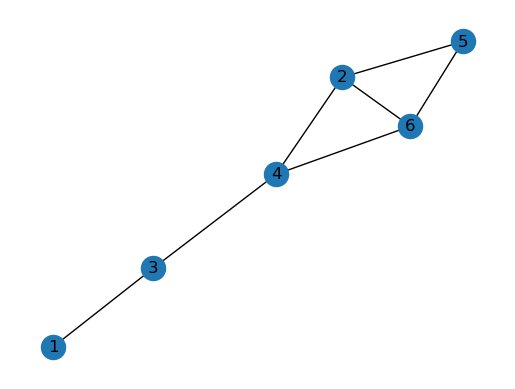

In [74]:
nx.draw_networkx(g)
plt.axis('off')  # turn off axis 
plt.show()   

+) graphML 파일로 저장하기

- graphML 파일로 내보낸 후, gephi 등의 툴로 시각화할 수도 있다


In [77]:
nx.write_graphml(g, 'graph/graph_test.graphml')

### node, edge에 attribute 더하기
1. Add node attributes

In [80]:
 g.nodes[1]['gender']='male'      # {'gender':'male'}이라는 dictionary의 느낌. key-value pair.
 g.nodes[2]['gender']='female'
 g.nodes[3]['gender']='male'
 g.nodes[4]['gender']='female'
 g.nodes[5]['gender']='male'
 g.nodes[6]['gender']='male'

 print(nx.get_node_attributes(g, 'gender'))

{1: 'male', 2: 'female', 3: 'male', 4: 'female', 5: 'male', 6: 'male'}


2. Add edge attributes

In [83]:
 g[1][3]['weight'] = 3    ## 이렇게 접근해도 됨: g.edges[1, 3]['weight'] = 3
 g[2][4]['weight'] = 1
 g[2][5]['weight'] = 4
 g[2][6]['weight'] = 3
 g[3][4]['weight'] = 2
 g[4][6]['weight'] = 3
 g[5][6]['weight'] = 4

 print(nx.get_edge_attributes(g, 'weight'))

{(1, 3): 3, (2, 4): 1, (2, 5): 4, (2, 6): 3, (3, 4): 2, (4, 6): 3, (5, 6): 4}


- 1-3 사이의 edge를 접근하는 방법: g[1][3] = g.edges[1, 3] (어떻게 접근하든 상관없음)

+) 속성까지 포함해서 node, edge 보기

- data=True 옵션을 넣어주면 됨

In [87]:
g.nodes(data=True)  ## node들의 속성까지 함께 볼 수 있음

NodeDataView({1: {'gender': 'male'}, 2: {'gender': 'female'}, 3: {'gender': 'male'}, 4: {'gender': 'female'}, 5: {'gender': 'male'}, 6: {'gender': 'male'}})

In [89]:
g.edges(data=True)  ## edge들의 속성까지 함께 볼 수 있음

EdgeDataView([(1, 3, {'weight': 3}), (2, 4, {'weight': 1}), (2, 5, {'weight': 4}), (2, 6, {'weight': 3}), (3, 4, {'weight': 2}), (4, 6, {'weight': 3}), (5, 6, {'weight': 4})])

### attribute 포함해서 시각화

1.edge의 ‘weight’를 포함해서 시각화

In [93]:
pos=nx.spring_layout(g)  # 각 node의 position을 정해서 그려줘야 edge_label를 맞춰서 넣을 수 있음
nx.draw_networkx(g, pos)

labels = nx.get_edge_attributes(g,'weight')
nx.draw_networkx_edge_labels(g, pos, edge_labels=labels)

plt.axis('off')  # turn off axis 
plt.show()

2. node의 ‘gender’ attribute에 따라 색 다르게 표현

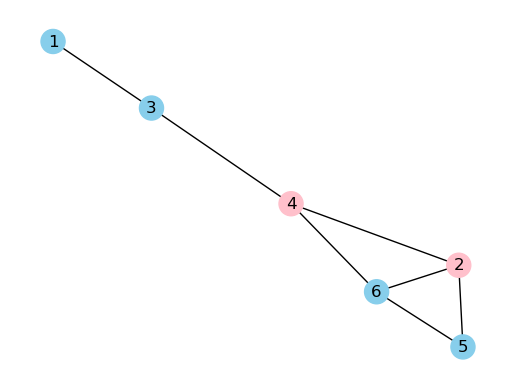

In [96]:
color_map = []
for n, d in g.nodes(data=True):
    if d['gender'] == 'female':
        color_map.append('pink')   # 여성: pink
    else: 
        color_map.append('skyblue')   # 남성: skyblue

    pos=nx.spring_layout(g)
    
nx.draw_networkx(g, pos, node_color=color_map)

labels = nx.get_edge_attributes(g,'weight')
plt.axis('off')  # turn off axis 
plt.show()

### DiGraph 그리기 & self-loop

In [99]:
diG = nx.DiGraph()
diG.add_edges_from([(1, 2), (2, 4), (4, 2), (3, 3), (1, 3), (5, 1)]) # edge만 추가해도, 자동으로 이에 포함된 node도 함께 추가됨


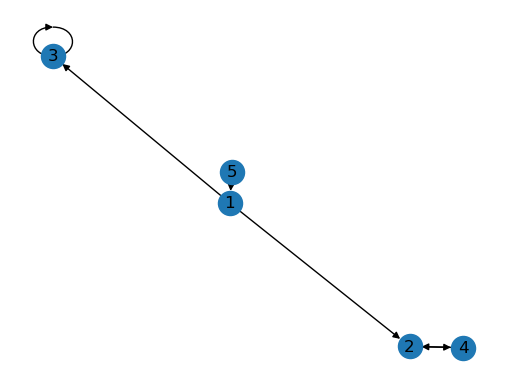

In [101]:
nx.draw_networkx(diG)
plt.axis('off')  # turn off axis 
plt.show()


+) self-loop 확인하기

self-loop: 자기 자신으로 돌아오는 루프 (edge that begin and end on the same node)
ex) 버스 노선 중, A 플랫폼에서 떠나서 A 플랫폼으로 돌아오는 순환선이 self-loop로 표현될 수 있음.
이번 diG에서 추가한 (3, 3) edge가 바로 self-loop
self-loop는 그래프를 시각화했을 때 잘 눈에 띄지 않기에, nx.number_of_selfloops()함수로 self-loop의 개수를 파악할 수 있다.

In [104]:
nx.number_of_selfloops(diG)   # diG에는 1개의 self-loop가 포함되어 있음


1

### Network 구조 파악하기

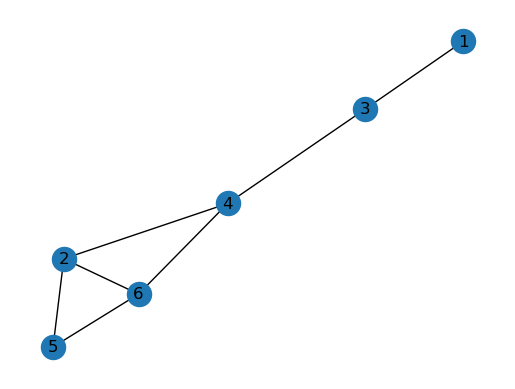

In [107]:
# 위에서 생성한 g 네트워크를 이어서 사용
nx.draw_networkx(g)
plt.axis('off')  # turn off axis 
plt.show()  

#### Neighbors & Degree
- g.neighbors(node): 그래프 g 내에서 특정 node와 연결된 neighbor node들을 파악할 수 있음
- g.degree(node): 그래프 g 내에서 특정 node의 neighbor 수를 파악할 수 있음. (연결된 node의 수)


In [110]:
print(list(g.neighbors(4))) # 4's neighbors  
print(g.degree(4)) # 4's degree, i.e., number of neighbors


[2, 3, 6]
3


### Centrality
##### : node의 중요성을 판별할 때 활용.

1 Degree Centrality: tie가 얼마나 많은지의 정도
- 특정 node의 neighbor 수 / 최대로 가질 수 있는 neighbor 수 = degree / (n-1)
- 최대로 가질 수 있는 neighbor 수는 n-1. (self-loop 고려X)

In [113]:
 # 각 node별 degree centrality 값을 dictionary 형태로 보여줌
nx.degree_centrality(g)  # key: node, value: degree centrality score for that node


{1: 0.2,
 2: 0.6000000000000001,
 3: 0.4,
 4: 0.6000000000000001,
 5: 0.4,
 6: 0.6000000000000001}

2. Betweenness Centrality: 얼마나 bridge 역할을 하는지의 정도
- 특정 node를 지나가는 shortest path의 수 / 모든 가능한 shortest path의 수
- 여러 집단을 이어주는 역할을 하는 node를 파악할 때 용이 (ex. 정치 관심 그룹과 예술 관심 그룹을 이어주는 역할을 하는 node 파악)

In [116]:
# 각 node별 betweenness centrality 값을 dictionary 형태로 보여줌
nx.betweenness_centrality(g)


{1: 0.0,
 2: 0.15000000000000002,
 3: 0.4,
 4: 0.6000000000000001,
 5: 0.0,
 6: 0.15000000000000002}

+) nx.betweenness_centrality(g, weight='weight')라고 weight 옵션을 적어주면, 각 edge의 weight를 고려해서 centrality를 계산

In [119]:
nx.betweenness_centrality(g, weight='weight')

{1: 0.0, 2: 0.30000000000000004, 3: 0.4, 4: 0.6000000000000001, 5: 0.0, 6: 0.0}

3. Closeness Centrality: 다른 node들과 얼마나 close하게 연결되어 있나
- 특정 node에서의 다른 node까지의 shortest path를 고려
- (n-1) / 특정 node에서 다른 모든 node까지의 shortest path distance의 합
- n-1은 sum of minimum possible distances. (모든 다른 node까지 1로 가는 게 minimum이니까)
- 분모(특정 node에서 다른 모든 node까지의 shortest path distance의 합)가 작을수록 central한 것이므로, closeness centraliy 값은 높을수록 더 중요도가 높은 것!

In [122]:
# 각 node별 closeness centrality 값을 dictionary 형태로 보여줌
nx.closeness_centrality(g)


{1: 0.38461538461538464,
 2: 0.625,
 3: 0.5555555555555556,
 4: 0.7142857142857143,
 5: 0.45454545454545453,
 6: 0.625}

3. PageRAnk Centrality:  페이지 랭크의 값은 임의로 k번 움직일 때 각 노드에 머무르게 될 확률을 의미
- "하이퍼링크 네트워크 구조에서 웹페이지들의 중요성을 어떻게 측정할까"에 대한 고민으로 구글이 개발
- 핵심 개념 및 가정 : 중요한 노드들은 또다른 중요한 페이지로부터 많은 유입 링크를 가진다.
- 방향성을 가진 네트워크에 효과적
- 한 노드의 페이지랭크 점수는 다른 노드의 페이지랭크 점수에 의존적 (따라서 여러번 반복적으로-순환적Circular으로- 계산하고 업데이트 해야함)

In [125]:
nx.pagerank(g)

{1: 0.10620066808884213,
 2: 0.17915497155466953,
 3: 0.15921532675809708,
 4: 0.1551035321492082,
 5: 0.17705363267028434,
 6: 0.2232718687788987}

+) nx.pagerank(g, weight='weight')라고 weight 옵션을 적어주면, 각 edge의 weight를 고려해서 centrality를 계산

In [128]:
nx.pagerank(g, weight='weight')

{1: 0.10620066808884213,
 2: 0.17915497155466953,
 3: 0.15921532675809708,
 4: 0.1551035321492082,
 5: 0.17705363267028434,
 6: 0.2232718687788987}